# LangGraph 기본 사용법 - 메시지 상태 업데이트**

### 학습 내용
1. LangGraph의 State 개념 이해
2. 메시지 기반 상태 업데이트
3. add_messages 리듀서 활용
4. invoke/stream/astream 비교 및 사용법
5. 스트림 모드별 차이점 이해

# 환경 설정

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("API Key가 설정되었습니다.")

API Key가 설정되었습니다.


# 챗봇 메시지 상태 관리 [수동 누적]


In [27]:
from langchain_core.messages import AnyMessage, HumanMessage, AIMessage
from typing_extensions import TypedDict
# AnyMessage: HumanMessage, AIMessage, SystemMessage 등을 모두 포괄하는 메시지 타입 (Union 타입)

# State 정의
class State(TypedDict):
    messages: list[AnyMessage]
    # ⚠️ Annotated[list, add_messages] 같은 리듀서가 지정되어 있지 않음
    # -> 노드가 반환하는 messages 값은 기존 값을 그냥 "통째로 덮어씌움" (자동 누적 X)
    # 그래서 누적을 하려면 노드 내부에서 직접 "기존 + 새 메시지" 형태로 만들어 반환해야 함

In [28]:
# 노드 정의 - 메시지를 수동으로 누적
from langchain.chat_models import init_chat_model

def node(state: State):
    messages = state["messages"]  # 지금까지 쌓인 메시지 리스트를 꺼냄
    llm = init_chat_model("gpt-5-mini")  # 모델 인스턴스 생성 (매 호출마다 새로 만들어짐 - 비효율적)
    response = llm.invoke(messages)  # 전체 대화 내역을 LLM에 전달해서 응답 받기

    return {"messages": messages + [response]}
    # 리듀서가 없으므로, 직접 "기존 messages + 새 응답"을 합쳐서 반환해야
    # 다음 노드(또는 최종 결과)에 "누적된" 전체 대화가 반영됨
    # (만약 그냥 {"messages": [response]}만 반환하면, 리듀서가 없어서
    #  이전 messages가 통째로 사라지고 response 1개만 남게 됨)

In [29]:
from langgraph.graph import StateGraph

# 그래프 빌더 생성
graph_builder = StateGraph(State)
graph_builder.add_node("node", node)
graph_builder.set_entry_point("node")  # add_edge(START, "node")와 동일한 역할 (시작점 지정의 다른 표현 방식)
graph = graph_builder.compile()

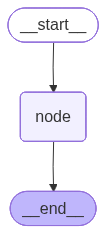

In [5]:
# 그래프 시각화
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(e)

In [31]:
result = graph.invoke({"messages": [HumanMessage("AI 에이전트란 뭐야?")]})
# 그래프 실행 -> node가 호출되어 LLM 응답을 받고, messages에 누적된 결과가 반환됨
# 초기 messages: [HumanMessage("AI 에이전트란 뭐야?")]
# node 실행 후: [HumanMessage(질문), AIMessage(응답)]  (수동으로 + [response] 했기 때문에 누적됨)

print("\n실행 결과:")
print(result)
# result는 {"messages": [HumanMessage(...), AIMessage(...)]} 형태의 dict
# print()로 찍으면 메시지 객체들의 repr 형태(타입, content, id 등)가 그대로 출력됨


실행 결과:
{'messages': [HumanMessage(content='AI 에이전트란 뭐야?', additional_kwargs={}, response_metadata={}), AIMessage(content='간단히 말하면, AI 에이전트는 목표를 달성하기 위해 주변(환경)을 관찰하고(인지), 판단을 내리고(계획), 행동(출력·조치)을 하는 소프트웨어(또는 로봇)입니다.\n\n주요 특징\n- 목적 지향적: 특정 목표(예: 문의에 답하기, 물건 배송, 게임에서 이기기)를 수행하려고 행동합니다.\n- 인지–판단–행동 루프: 센서나 입력으로 환경을 관찰 → 내부 상태/모델로 판단 → 행동(응답, 명령 전송 등)을 취함.\n- 자율성 수준: 사람이 지시해줘야만 움직이는 것부터 스스로 계획·학습하는 고도 자율형까지 다양합니다.\n- 학습·적응: 많은 AI 에이전트는 경험을 통해 성능을 개선(머신러닝, 강화학습 등)합니다.\n- 환경과 상호작용: 다른 에이전트나 사용자와 협력·경쟁할 수 있습니다(멀티에이전트 시스템).\n\n종류(예)\n- 대화형 에이전트: 챗봇, 가상비서(예: Siri, Alexa, ChatGPT 기반 봇)\n- 로봇 에이전트: 자율주행차, 물류 로봇\n- 소프트웨어 에이전트: 추천시스템, 자동 매매 알고리즘\n- 게임 에이전트: NPC나 강화학습으로 학습한 플레이어\n\n구성 요소(단순화)\n- 입력(센서, API 호출 등)\n- 내부 모델/상태(지식 베이스, 신경망 등)\n- 계획/의사결정 모듈(규칙, 최적화, RL 등)\n- 출력(행동, 응답, 제어 신호)\n\n주의할 점 / 윤리적 고려\n- 안전성·신뢰성(오작동 시 피해 가능)\n- 편향·프라이버시 문제\n- 책임 소재(결정 결과에 대한 책임)\n\n더 궁금한 점 있으면 예시를 하나 골라서 그 에이전트가 어떻게 동작하는지 단계별로 설명해줄게요. 어떤 사례가 궁금하나요?', additional_kwargs={'refusal': None}, response_metadata={'token_

In [32]:
for msg in result["messages"]:
    msg.pretty_print()
    # pretty_print(): 메시지 객체를 사람이 보기 좋은 형태로 콘솔에 출력하는 메서드
    # "================ Human Message ================" 같은 구분선과 함께
    # 역할(Human/AI)과 내용(content)만 깔끔하게 보여줌
    # (print(msg)처럼 id, additional_kwargs 같은 부가 정보는 생략되고 핵심만 표시됨)

================================ Human Message =================================

AI 에이전트란 뭐야?
================================== Ai Message ==================================

간단히 말하면, AI 에이전트는 목표를 달성하기 위해 주변(환경)을 관찰하고(인지), 판단을 내리고(계획), 행동(출력·조치)을 하는 소프트웨어(또는 로봇)입니다.

주요 특징
- 목적 지향적: 특정 목표(예: 문의에 답하기, 물건 배송, 게임에서 이기기)를 수행하려고 행동합니다.
- 인지–판단–행동 루프: 센서나 입력으로 환경을 관찰 → 내부 상태/모델로 판단 → 행동(응답, 명령 전송 등)을 취함.
- 자율성 수준: 사람이 지시해줘야만 움직이는 것부터 스스로 계획·학습하는 고도 자율형까지 다양합니다.
- 학습·적응: 많은 AI 에이전트는 경험을 통해 성능을 개선(머신러닝, 강화학습 등)합니다.
- 환경과 상호작용: 다른 에이전트나 사용자와 협력·경쟁할 수 있습니다(멀티에이전트 시스템).

종류(예)
- 대화형 에이전트: 챗봇, 가상비서(예: Siri, Alexa, ChatGPT 기반 봇)
- 로봇 에이전트: 자율주행차, 물류 로봇
- 소프트웨어 에이전트: 추천시스템, 자동 매매 알고리즘
- 게임 에이전트: NPC나 강화학습으로 학습한 플레이어

구성 요소(단순화)
- 입력(센서, API 호출 등)
- 내부 모델/상태(지식 베이스, 신경망 등)
- 계획/의사결정 모듈(규칙, 최적화, RL 등)
- 출력(행동, 응답, 제어 신호)

주의할 점 / 윤리적 고려
- 안전성·신뢰성(오작동 시 피해 가능)
- 편향·프라이버시 문제
- 책임 소재(결정 결과에 대한 책임)

더 궁금한 점 있으면 예시를 하나 골라서 그 에이전트가 어떻게 동작하는지 단계별로 설명해줄게요. 어떤 사례가 궁금하나요?


# add_messages 리듀서로 [자동 누적]

`add_messages`는 메시지를 자동으로 누적하는 **리듀서(reducer)** 함수입니다.

https://reference.langchain.com/python/langgraph/graph/message/add_messages


- 메시지 자동 병합
- 중복 메시지 ID 처리
- 코드 간소화
- 메시지 수정 및 삭제 지원

## add_messages 기본 사용법

In [33]:
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.graph.message import add_messages

msgs1 = [HumanMessage(content="Hello", id="1")]  # 기존 메시지 리스트 (id="1")
msgs2 = [AIMessage(content="Hi there!", id="2")]  # 새로 추가될 메시지 리스트 (id="2", 다른 id)

add_messages(msgs1, msgs2)
# add_messages(기존, 새값) -> id가 다르므로 단순히 뒤에 이어붙임
# 결과: [HumanMessage(id="1", "Hello"), AIMessage(id="2", "Hi there!")]

[HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='1'),
 AIMessage(content='Hi there!', additional_kwargs={}, response_metadata={}, id='2', tool_calls=[], invalid_tool_calls=[])]

In [34]:
# 동일 ID로 메시지 업데이트
msgs1 = [HumanMessage(content="첫 번째 메시지", id="1")]
msgs2 = [HumanMessage(content="수정된 메시지", id="1")]  # 동일 ID

result = add_messages(msgs1, msgs2)
# id가 같으면 "추가"가 아니라 "교체(수정)"로 처리됨
# -> 기존 id="1" 메시지가 사라지고, 새 id="1" 메시지로 덮어씌워짐
# (id가 다르면 누적, id가 같으면 수정 -> 이게 add_messages의 핵심 동작)

print("\nID가 같은 경우 (메시지 수정):")
for msg in result:
    print(f"{type(msg).__name__} (id={msg.id}): {msg.content}")
# 실행 결과: HumanMessage (id=1): 수정된 메시지
# -> 리스트에 메시지가 1개만 남고, content가 "수정된 메시지"로 바뀜


ID가 같은 경우 (메시지 수정):
HumanMessage (id=1): 수정된 메시지


# add_messages 를 리듀서로 사용하기

In [36]:
from typing_extensions import Annotated
from langgraph.graph.message import add_messages

# 그래프 전체에서 공유되는 State 정의
# messages 필드는 add_messages 리듀서를 사용 -> 새 메시지가 들어오면 기존 리스트에 자동으로 누적(append)됨
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [37]:
def node(state: State):
    # gpt-5-mini 모델 초기화
    llm = init_chat_model("gpt-5-mini")
    
    # 현재까지 누적된 messages 전체를 LLM에 전달해서 응답 생성
    response = llm.invoke(state["messages"])

    # 새로 생성된 응답만 반환하면 됨
    # (add_messages 리듀서가 기존 state["messages"]에 자동으로 합쳐줌, 직접 합칠 필요 없음)
    return {"messages": response}

In [38]:
# StateGraph 객체 생성, 위에서 정의한 State 스키마 사용
graph_builder = StateGraph(State)

# "node"라는 이름으로 node 함수를 그래프에 노드로 등록
graph_builder.add_node("node", node)

# 그래프 실행 시 시작점(entry point)을 "node"로 지정
graph_builder.set_entry_point("node")

# 그래프를 실행 가능한 형태로 컴파일
graph = graph_builder.compile()

In [40]:
# 그래프 실행
# 사용자 입력 메시지를 딕셔너리 형태로 정의 (role과 content 지정)
input_message = {"role": "user", "content": "안녕하세요."}

# graph.invoke()로 그래프 실행
# 초기 state로 messages 리스트에 input_message를 담아서 전달
result = graph.invoke({"messages": [input_message]})

# 실행 결과(최종 state) 전체를 출력 -> {"messages": [...]} 형태
print(result)

print("\n메시지 출력:")
# result["messages"]에는 사용자 메시지 + AI 응답 메시지가 누적되어 있음
for message in result["messages"]:
    # pretty_print()로 메시지 타입(Human/AI)과 내용을 보기 좋게 출력
    message.pretty_print()

{'messages': [HumanMessage(content='안녕하세요.', additional_kwargs={}, response_metadata={}, id='63e078ac-a551-4404-b99c-df0bb822b049'), AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 84, 'prompt_tokens': 9, 'total_tokens': 93, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Ds3eYtpIRgekgIif6H6wjCVqXvC5L', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eda22-0e45-7753-be20-58e30eef35ed-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 84, 'total_tokens': 93, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning'

In [41]:
# result["messages"] 리스트의 길이 출력 -> 누적된 메시지 총 개수 확인
print(f"메시지 개수: {len(result['messages'])}")

메시지 개수: 2


# LLM 연결하여 대화형 챗봇 그래프 만들기

In [42]:
from typing_extensions import Annotated
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph
from langchain.chat_models import init_chat_model

# gpt-5.4-mini 모델로 LLM 초기화
llm = init_chat_model(
    "gpt-5.4-mini"
)

# State 정의
# messages 필드는 add_messages 리듀서 사용 -> 새 메시지가 자동으로 기존 리스트에 누적됨
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

# 챗봇 노드
def chatbot(state: State):
    # 현재까지 누적된 messages를 LLM에 전달해서 응답 생성
    response = llm.invoke(state["messages"])
    return {"messages": response} # AIMessage 객체 (add_messages가 자동으로 기존 messages에 추가)

# 그래프 구성
graph_builder = StateGraph(State)          # State 스키마로 그래프 빌더 생성
graph_builder.add_node("chatbot", chatbot) # "chatbot" 노드 등록
graph_builder.set_entry_point("chatbot")   # 그래프 시작점을 "chatbot"으로 지정
graph = graph_builder.compile()            # 실행 가능한 그래프로 컴파일

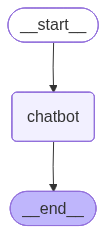

In [16]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(e)

##  invoke - 일반 호출

In [43]:
# invoke - 동기 방식 (요청을 보내고 전체 응답이 완성될 때까지 기다림)
user_message = HumanMessage("Python의 장점을 3가지만 알려주세요.")

# 그래프 실행 -> 동기 방식이므로 응답이 다 끝날 때까지 블로킹됨
result = graph.invoke({"messages": [user_message]})

print("\n[invoke 결과]")
# 누적된 messages(사용자 질문 + AI 응답)를 순서대로 출력
for msg in result["messages"]:
    msg.pretty_print()


[invoke 결과]
================================ Human Message =================================

Python의 장점을 3가지만 알려주세요.
================================== Ai Message ==================================

물론입니다. Python의 장점 3가지는 다음과 같습니다.

1. **문법이 간단하고 읽기 쉽다**  
   Python은 코드가 직관적이라 처음 배우기 쉽고, 유지보수도 편합니다.

2. **활용 범위가 넓다**  
   웹 개발, 데이터 분석, 인공지능, 자동화, 게임 개발 등 다양한 분야에서 사용할 수 있습니다.

3. **풍부한 라이브러리와 커뮤니티**  
   필요한 기능을 쉽게 구현할 수 있는 라이브러리가 많고, 전 세계적으로 사용자가 많아 자료와 도움을 찾기 쉽습니다.

원하시면 **Python의 단점 3가지**도 함께 알려드릴게요.


In [44]:
print(result)

{'messages': [HumanMessage(content='Python의 장점을 3가지만 알려주세요.', additional_kwargs={}, response_metadata={}, id='98c3d23d-bc06-4424-93c5-f786719b6808'), AIMessage(content='물론입니다. Python의 장점 3가지는 다음과 같습니다.\n\n1. **문법이 간단하고 읽기 쉽다**  \n   Python은 코드가 직관적이라 처음 배우기 쉽고, 유지보수도 편합니다.\n\n2. **활용 범위가 넓다**  \n   웹 개발, 데이터 분석, 인공지능, 자동화, 게임 개발 등 다양한 분야에서 사용할 수 있습니다.\n\n3. **풍부한 라이브러리와 커뮤니티**  \n   필요한 기능을 쉽게 구현할 수 있는 라이브러리가 많고, 전 세계적으로 사용자가 많아 자료와 도움을 찾기 쉽습니다.\n\n원하시면 **Python의 단점 3가지**도 함께 알려드릴게요.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 161, 'prompt_tokens': 17, 'total_tokens': 178, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-mini-2026-03-17', 'system_fingerprint': None, 'id': 'chatcmpl-Ds3gdFrCPptJ40sd3QxnTkDGyeFLq', 'service_tier': 'd

##  stream - 스트리밍 호출

`stream`은 중간 결과를 실시간으로 반환합니다.

### 스트림 모드

- **values**: 각 단계의 전체 상태 출력
- **updates**: 각 단계의 업데이트만 출력 (기본값)
- **messages**: 메시지와 메타데이터 출력

https://docs.langchain.com/oss/python/langgraph/streaming#stream-modes


stream_mode="values" - 매 단계마다 "전체 상태(state)"를 그대로 반환

In [45]:
# stream_mode="values" - 매 단계마다 "전체 상태(state)"를 그대로 반환
print("\n[stream - values 모드]")
user_message = HumanMessage("LangGraph란 무엇인가요?")

# graph.stream()으로 그래프 실행 -> 노드가 실행될 때마다 chunk 단위로 결과를 받음
# stream_mode="values"는 매 단계의 누적된 전체 state 딕셔너리를 그대로 넘겨줌
for chunk in graph.stream({"messages": [user_message]}, stream_mode="values"):
    print("\n=== 현재 상태 ===")
    # chunk는 {"messages": [...]} 형태의 딕셔너리
    for state_key, state_value in chunk.items():
        if state_key == "messages":
            # 현재까지 누적된 메시지 개수 출력
            print(f"메시지 개수: {len(state_value)}")
            # 가장 최근에 추가된 메시지만 보기 좋게 출력
            state_value[-1].pretty_print()


[stream - values 모드]

=== 현재 상태 ===
메시지 개수: 1
================================ Human Message =================================

LangGraph란 무엇인가요?

=== 현재 상태 ===
메시지 개수: 2
================================== Ai Message ==================================

LangGraph는 **LLM(대규모 언어 모델) 애플리케이션을 상태 기반 그래프로 설계하고 실행하기 위한 프레임워크**입니다.  
쉽게 말해, “에이전트/워크플로를 **노드(Node)** 와 **엣지(Edge)** 로 연결해, 복잡한 대화 흐름이나 반복 작업을 안정적으로 만들 수 있게 해주는 도구”입니다.

## 핵심 개념
- **노드(Node)**: 특정 작업을 수행하는 단계  
  예: 사용자 입력 처리, 검색, 요약, 답변 생성
- **엣지(Edge)**: 다음에 어떤 노드로 이동할지 결정하는 연결
- **상태(State)**: 그래프 전체에서 공유되는 데이터  
  예: 대화 기록, 검색 결과, 중간 추론 결과
- **조건 분기/루프**: 필요하면 여러 번 반복하거나, 상황에 따라 다른 경로로 이동 가능

## LangChain과의 차이
- **LangChain**: LLM을 쉽게 연결하는 라이브러리(프롬프트, 체인, 툴 호출 등)
- **LangGraph**: 그 위에서 **복잡한 제어 흐름**을 더 잘 다루는 프레임워크  
  - 반복 실행
  - 분기 처리
  - 상태 유지
  - 멀티 에이전트 협업

즉, **LangChain이 “부품”이라면, LangGraph는 “흐름도”를 만드는 데 강하다**고 볼 수 있습니다.

## 이런 경우에 유용합니다
- 에이전트가 **도구를 여러 번 사용**해야 할 때
- 결과를 보고 **다시 생각하거나 재시도**해야 할 때
- 사람의 승인(Human-in-the-lo

stream_mode="updates" - 각 노드가 "새로 반환한 값(변경분)"만 전달 (기본값)

In [46]:
# stream_mode="updates" - 각 노드가 "새로 반환한 값(변경분)"만 전달 (기본값)
print("\n[stream - updates 모드 (기본값)]")
user_message = HumanMessage("AI의 미래는 어떻게 될까요?")

# stream_mode="updates"는 values 모드와 달리 전체 state가 아니라
# 노드 실행 후 반환된 업데이트 내용만 {노드이름: 반환값} 형태로 전달
for chunk in graph.stream({"messages": [user_message]}, stream_mode="updates"):
    print("\n=== 업데이트 ===")
    # chunk 예시: {"chatbot": {"messages": AIMessage(...)}}
    for node, value in chunk.items():
        print(f"노드: {node}")  # 어떤 노드에서 발생한 업데이트인지 출력
        if "messages" in value:
            # 해당 노드가 새로 생성한 메시지의 내용만 출력 (누적 전체가 아님)
            print(f"내용: {value['messages'].content}")


[stream - updates 모드 (기본값)]

=== 업데이트 ===
노드: chatbot
내용: AI의 미래는 한마디로 말하면 **“더 강력해지고, 더 넓게 퍼지고, 더 많이 규제될 것”**입니다.  
조금 더 풀어보면 이런 방향으로 갈 가능성이 큽니다.

### 1) 일상생활에 더 깊이 들어옵니다
지금은 챗봇이나 이미지 생성이 대표적이지만, 앞으로는  
- 이메일 작성
- 일정 관리
- 검색과 요약
- 쇼핑 추천
- 학습 보조
- 건강 관리 보조  
같은 기능이 **사람의 기본 도구**처럼 자연스럽게 붙게 될 가능성이 큽니다.

### 2) 업무 방식이 크게 바뀝니다
AI는 많은 일을 “대체”하기보다 먼저 **보조하고 자동화**할 것입니다.  
특히 다음 분야에서 변화가 큽니다.
- 사무/행정
- 고객응대
- 번역
- 콘텐츠 제작
- 프로그래밍
- 데이터 분석

즉, “AI가 사람을 완전히 없앤다”기보다 **AI를 잘 쓰는 사람이 더 강해지는 구조**가 될 가능성이 큽니다.

### 3) 더 똑똑한 AI 에이전트가 등장합니다
앞으로는 단순히 답만 하는 AI보다  
**목표를 주면 여러 단계를 알아서 수행하는 AI**가 중요해집니다.  
예:
- “이번 주 출장 준비해줘”
- “이 시장 조사해서 보고서 초안 만들어줘”
- “내 업무 우선순위 정리해줘”

이런 **에이전트형 AI**가 커질 가능성이 큽니다.

### 4) 개인화가 훨씬 강해집니다
미래의 AI는 모든 사람에게 똑같이 답하는 것이 아니라,  
- 내 말투
- 내 업무 스타일
- 내 지식 수준
- 내 취향  
에 맞춰 **개인 비서처럼** 동작할 가능성이 큽니다.

### 5) 위험과 규제도 함께 커집니다
기술이 강해질수록 우려도 커집니다.
- 허위정보
- 딥페이크
- 개인정보 침해
- 일자리 충격
- AI 판단의 책임 문제
- 군사적 악용 가능성

그래서 앞으로는 기술 발전만큼이나  
**법, 윤리, 안전장치, 투명성**이 중요해질 것입니다.

### 6) “범용 인공지능(AGI)” 논의가

stream_mode="messages" - 메시지와 메타데이터

In [47]:
# stream_mode="messages" - LLM 토큰 단위 스트리밍 + 메타데이터
print("\n[stream - messages 모드]")
user_message = HumanMessage("AI 란?")

# stream_mode="messages"는 LLM이 토큰을 생성하는 즉시 (chunk_msg, metadata) 튜플로 전달
# chunk_msg: 토큰 단위로 쪼개진 메시지 조각, metadata: 어떤 노드/LLM 호출에서 나온 것인지 등의 정보
for chunk_msg, metadata in graph.stream({"messages": [user_message]}, stream_mode="messages"):
    # 줄바꿈 없이 이어서 출력해서 실시간 타이핑처럼 보이게 함
    print(chunk_msg.content, end="", flush=True)


[stream - messages 모드]
AI는 **인공지능(Artificial Intelligence)**의 줄임말로,  
사람처럼 **학습하고, 판단하고, 문제를 해결하는 컴퓨터 기술**을 말합니다.

예를 들면:
- 음성 인식: “시리야”, “헤이 구글”
- 추천 시스템: 유튜브, 넷플릭스 추천
- 번역: 자동 번역
- 챗봇: 대화형 AI
- 자율주행: 스스로 길을 판단하는 기술

쉽게 말해,  
**AI는 컴퓨터가 사람의 지능 일부를 흉내 내도록 만든 기술**입니다.

원하시면 제가  
**“AI를 아주 쉽게 한 문장으로 설명”**하거나  
**“AI의 종류”**도 알려드릴게요.

## astream - 비동기 스트리밍

`astream`은 비동기 방식으로 스트리밍을 처리합니다.

In [48]:
# astream - 비동기 스트리밍
import asyncio

async def async_stream_example():
    print("\n[astream - 비동기 스트리밍]")
    user_message = HumanMessage("LangChain의 주요 기능을 설명해주세요.")

    # astream()은 stream()의 비동기 버전 -> async for로 토큰 단위 결과를 받음
    # 비동기이므로 이 작업이 I/O를 기다리는 동안 다른 코드를 블로킹하지 않음
    async for chunk_msg, metadata in graph.astream(
        {"messages": [user_message]},
        stream_mode="messages"
    ):
        print(chunk_msg.content, end="", flush=True)
        # print(f"청크: {chunk_msg.content}")
        # print(f"노드: {metadata.get('langgraph_node', 'N/A')}")  # metadata로 어떤 노드에서 나온 토큰인지 확인 가능
        # print("---")

# Jupyter에서 비동기 실행
# 일반 .py 스크립트라면 asyncio.run(async_stream_example())를 써야 하지만,
# Jupyter는 이미 자체 이벤트 루프가 돌고 있어서 await를 바로 사용 가능
await async_stream_example()


[astream - 비동기 스트리밍]
LangChain은 **대규모 언어 모델(LLM)**을 활용한 애플리케이션을 더 쉽게 만들기 위한 프레임워크입니다.  
핵심 기능은 다음과 같습니다.

### 1. LLM 연동
- OpenAI, Anthropic, Hugging Face 등 다양한 모델을 쉽게 연결할 수 있습니다.
- 모델 호출, 파라미터 설정, 응답 처리 등을 간단히 할 수 있습니다.

### 2. 프롬프트 관리
- 프롬프트 템플릿을 만들어 재사용할 수 있습니다.
- 입력값에 따라 동적으로 프롬프트를 생성할 수 있습니다.

### 3. 체인(Chains)
- 여러 작업을 순서대로 연결할 수 있습니다.
- 예: 문서 요약 → 질의응답 → 결과 정리 같은 흐름 구성

### 4. 에이전트(Agents)
- LLM이 상황에 따라 적절한 도구를 선택해 사용하도록 할 수 있습니다.
- 예: 검색, 계산, 데이터베이스 조회 같은 외부 도구 활용

### 5. 메모리(Memory)
- 대화 기록이나 상태를 저장해 이전 맥락을 반영할 수 있습니다.
- 챗봇처럼 대화 맥락이 중요한 서비스에 유용합니다.

### 6. 데이터 연결 및 검색(RAG)
- 문서, DB, 웹 데이터 등을 불러와 검색하고 LLM과 결합할 수 있습니다.
- 자체 문서를 바탕으로 답변하는 QA 시스템을 만들 때 많이 사용합니다.

### 7. 도구(Tools) 및 외부 시스템 연동
- API, 검색 엔진, 계산기, 코드 실행기 등과 연결할 수 있습니다.
- LLM을 단순 대화형이 아니라 실제 작업 수행형으로 확장할 수 있습니다.

### 8. 평가 및 관찰 가능성
- 실행 과정을 추적하고 디버깅하기 쉽게 도와줍니다.
- 프롬프트, 체인, 응답 흐름을 관리하며 성능 개선에 활용할 수 있습니다.

### 한 줄 요약
LangChain은 **LLM을 단독으로 쓰는 대신, 프롬프트·도구·메모리·검색·워크플로우를 연결해 실제 애플리케이션으로 만들기 위한 프레임워크**입니다.

원하시면 제가 이어서  
- *

##  ainvoke - 비동기 일반 호출

`ainvoke`는 비동기 방식으로 여러 요청을 동시에 처리할 수 있습니다.

In [49]:
# ainvoke - 비동기 호출 (invoke의 비동기 버전)
async def async_invoke_example():
    print("\n[ainvoke - 비동기 호출]")
    user_message = HumanMessage("간단히 인사해주세요.")

    # invoke와 동일하게 전체 응답을 한 번에 받지만, await로 비동기 처리
    # (다른 비동기 작업과 동시에 실행될 때 블로킹되지 않는다는 점이 invoke와의 차이)
    result = await graph.ainvoke({"messages": [user_message]})

    print("\n결과:")
    # 누적된 messages(사용자 질문 + AI 응답) 순서대로 출력
    for msg in result["messages"]:
        msg.pretty_print()

# 실행
await async_invoke_example()


[ainvoke - 비동기 호출]

결과:
================================ Human Message =================================

간단히 인사해주세요.
================================== Ai Message ==================================

안녕하세요! 무엇을 도와드릴까요?


## invoke & ainvoke

In [50]:
import time

start = time.time()  # 시작 시간 기록

results = []
# invoke는 동기 방식이므로 한 요청이 끝나야 다음 요청이 시작됨 -> 순차적으로 실행됨(직렬 처리)
results.append(graph.invoke({"messages": [HumanMessage("안녕")]}))
results.append(graph.invoke({"messages": [HumanMessage("오늘 날씨 어때?")]}))
results.append(graph.invoke({"messages": [HumanMessage("추천해줘")]}))

end = time.time()  # 종료 시간 기록
# 3개 요청을 순차적으로 처리한 총 소요 시간 출력 (이후 비동기/동시 실행과 속도 비교용)
print(f"동기 실행 시간: {end - start:.2f}초")

동기 실행 시간: 10.58초


In [51]:
import time
import asyncio

async def run_async():
    start = time.time()  # 시작 시간 기록

    # ainvoke()는 코루틴(coroutine)을 반환하므로, 호출만 해두면 아직 실행되지 않은 작업 객체가 됨
    tasks = [
        graph.ainvoke({"messages": [HumanMessage("안녕")]}),
        graph.ainvoke({"messages": [HumanMessage("오늘 날씨 어때?")]}),
        graph.ainvoke({"messages": [HumanMessage("추천해줘")]}),
    ]

    # asyncio.gather()로 3개 작업을 동시에 실행 -> 각 요청이 LLM 응답을 기다리는 동안
    # 서로 블로킹하지 않고 병렬로 처리되어 동기 방식보다 훨씬 빠름
    results = await asyncio.gather(*tasks)

    end = time.time()  # 종료 시간 기록
    # 3개 요청을 동시에 처리한 총 소요 시간 출력 (동기 실행 시간과 비교용)
    print(f"비동기 실행 시간: {end - start:.2f}초")

    return results

await run_async()

비동기 실행 시간: 2.35초


[{'messages': [HumanMessage(content='안녕', additional_kwargs={}, response_metadata={}, id='0fc1aebc-fa04-490b-8ada-6673db390a6e'),
   AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 8, 'total_tokens': 22, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-mini-2026-03-17', 'system_fingerprint': None, 'id': 'chatcmpl-Ds3lNEuvtkFP9C0UamYvv8MtuxDXi', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eda28-8296-7760-a6e3-465f5106c3d7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 14, 'total_tokens': 22, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning

---

# Streaming 공식 예제

https://docs.langchain.com/oss/python/langgraph/streaming#full-example


In [55]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.config import get_stream_writer


# State 정의 - topic(입력)과 joke(결과) 필드를 가짐
class State(TypedDict):
    topic: str
    joke: str


def generate_joke(state: State):
    # get_stream_writer()로 커스텀 데이터를 스트림에 실시간으로 흘려보낼 writer 객체 획득
    writer = get_stream_writer()
    
    # writer()로 커스텀 메시지 전송 -> stream_mode="custom"으로 받을 수 있음
    # (LLM 응답이 아니라 진행 상태 같은 임의의 데이터를 중간에 보내고 싶을 때 사용)
    writer({"status": "thinking of a joke..."})
    
    # 노드의 최종 결과 반환 -> state["joke"]에 저장됨
    return {"joke": f"Why did the {state['topic']} go to school? To get a sundae education!"}

# 그래프 구성 (메서드 체이닝 방식)
graph = (
    StateGraph(State)
    .add_node(generate_joke)              # 노드 추가 (함수 이름이 자동으로 노드 이름이 됨)
    .add_edge(START, "generate_joke")     # 시작점 -> generate_joke로 연결
    .add_edge("generate_joke", END)       # generate_joke -> 종료점으로 연결
    .compile()
)

# 여러 stream_mode를 리스트로 동시에 지정 가능
# 이 경우 각 chunk는 (모드이름, 데이터) 형태의 "튜플"로 반환됨 (딕셔너리 아님!)
for stream_mode, data in graph.stream(
    {"topic": "ice cream"},
    stream_mode=["updates", "custom"],
):
    if stream_mode == "updates":
        # updates 모드: {노드이름: 반환값} 형태
        for node_name, state in data.items():
            print(f"Node {node_name} updated: {state}")
    elif stream_mode == "custom":
        # custom 모드: writer()로 보낸 데이터가 그대로 전달됨
        print(f"Status: {data['status']}")

Status: thinking of a joke...
Node generate_joke updated: {'joke': 'Why did the ice cream go to school? To get a sundae education!'}
